# **Первичный анализ данных**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%matplotlib inline

In [ ]:
url_red = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
df_red = pd.read_csv(url_red, sep=';')

url_white = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
df_white = pd.read_csv(url_white, sep=';')

df_red['is_red'] = 1
df_white['is_red'] = 0

df = pd.concat([df_red, df_white], ignore_index=True)
print(f'{df.shape} - до удаления дупликатов')
print(f'{round(float(df.duplicated().sum() / df.shape[0]), 2) * 100} % дупликатов')
df = df.drop_duplicates().reset_index(drop=True)
print(f'{df.shape} - после удаления дупликатов')

df.head()

(6497, 13) - до удаления дупликатов
18.0 % дупликатов
(5320, 13) - после удаления дупликатов


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,1


В объединённом датасете красного и белого вина (6497 объектов), однако обнаружено 18% полных дубликатов (1177 строк), после удаления которых осталось 5320 уникальных образцов. Удаление дубликатов до разбиения необходимо, чтобы одинаковые объекты не попали одновременно в обучающую и тестовую выборки

In [ ]:
df.isna().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Пропуски отстутствуют во всех столбцах

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
train = X_train.assign(quality=y_train)

Выборка разделена в пропорции 80% на обучение (4256 объектов) и 20% на тест (1064 объекта) с фиксацией `random_state=42` для воспроизводимости. Такое соотношение оставляет достаточно данных для обучения и даёт репрезентативный тест. Разбиение выполнено со стратификацией по целевой переменной (`stratify=y`), чтобы сохранить одинаковые пропорции редких оценок (3, 4, 8, 9) в обеих выборках.

Если многократно проверять модели по одной и той же тестовой выборке, возникает переобучение под тест, из-за чего финальная оценка качества оказывается оптимистично завышенной.

In [ ]:
stats = train.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats['skew'] = train.skew()
stats['kurtosis'] = train.kurtosis()
stats

,mean,std,min,50%,max,skew,kurtosis
fixed acidity,7.224871,1.331543,4.20000,7.0000,15.90000,1.679917,4.622282
volatile acidity,0.343255,0.166621,0.08000,0.3000,1.58000,1.533118,3.137659
citric acid,0.318879,0.146528,0.00000,0.3100,1.66000,0.481519,2.679074
residual sugar,5.001938,4.449953,0.60000,2.7000,65.80000,1.806959,8.748806
chlorides,0.056600,0.036161,0.00900,0.0470,0.61100,5.090109,44.066971
free sulfur dioxide,29.992011,17.823704,1.00000,28.0000,289.00000,1.518608,11.690645
total sulfur dioxide,113.736960,56.553830,7.00000,115.7500,440.00000,0.062150,-0.287661
density,0.994502,0.002967,0.98711,0.9946,1.03898,0.803393,10.926586
pH,3.223658,0.160276,2.72000,3.2100,4.01000,0.429822,0.566406
sulphates,0.532775,0.146087,0.22000,0.5100,1.98000,1.491246,5.764276


In [ ]:
y_train.value_counts(sort=False)

,count
quality,
5,1402
6,1858
7,685
4,165
3,24
8,118
9,4


<Axes: xlabel='quality', ylabel='Count'>

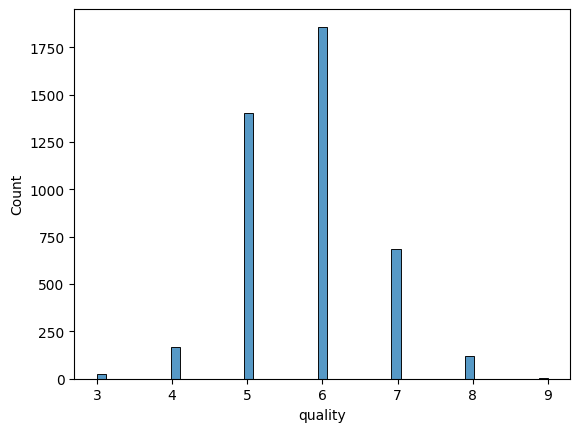

In [ ]:
sns.histplot(y_train)

Целевая переменная `quality` принимает дискретные значения от 3 до 9 и имеет сильный дисбаланс: более 92% обучающей выборки приходится на оценки 5 (1402), 6 (1858) и 7 (685), тогда как крайние классы представлены единичными примерами (3 — 24 шт., 9 — всего 4 шт.). Из-за этого моделям будет трудно предсказывать высокое или низкое качество.

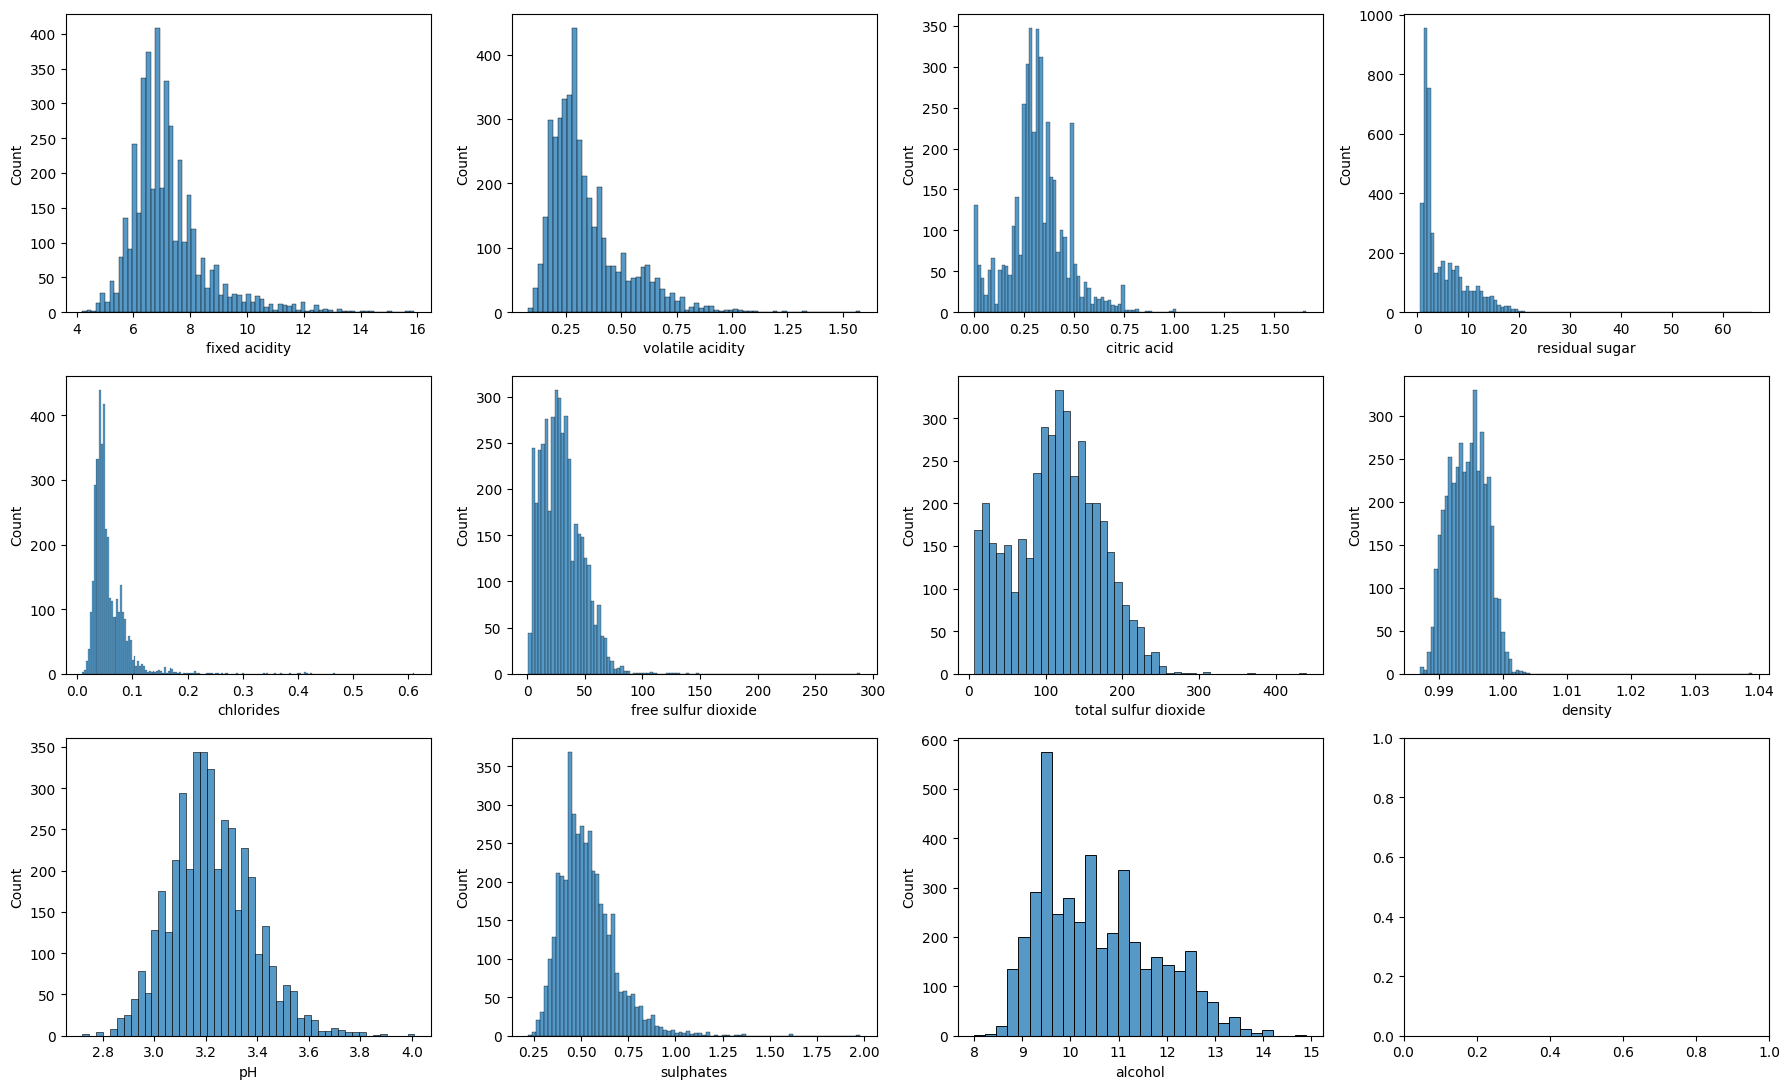

In [ ]:
feat_cols = [c for c in X.columns if c != 'is_red']

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), feat_cols):
    sns.histplot(train[c], ax=ax)

plt.tight_layout()
plt.show()

Признаки измерены в разных единицах и порядках величин (например, `density` около 0.99, а `total sulfur dioxide` доходит до 440), что требует масштабирования перед обучением линейных моделей. Большинство признаков имеют правостороннюю асимметрию и выбросы (особенно `chlorides`, а также `residual` `sugar` и `free sulfur dioxide`)

is_red,0,1
fixed acidity,6.834434,8.356136
volatile acidity,0.279755,0.527244
citric acid,0.334336,0.274093
residual sugar,5.852244,2.538233
chlorides,0.046027,0.087235
free sulfur dioxide,34.815898,16.015110
total sulfur dioxide,136.763274,47.019689
density,0.993734,0.996726
pH,3.194346,3.308590
sulphates,0.490066,0.656520


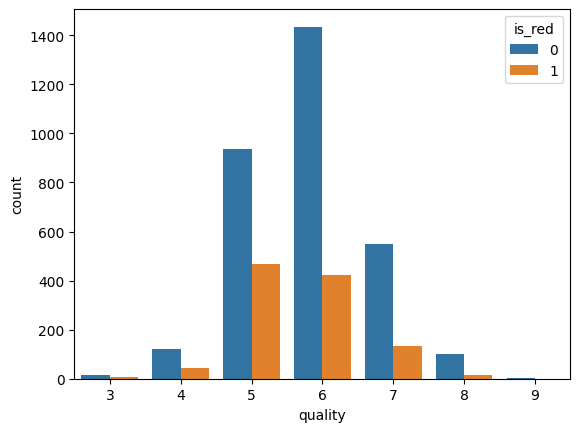

In [ ]:
train.groupby('is_red')['quality'].agg(['count', 'mean', 'std'])
sns.countplot(data=train, x='quality', hue='is_red')
train.groupby('is_red').mean().T

Белых вин в выборке около 74%, красных — 26%. Они существенно различаются химически: в красных винах выше летучая кислотность (0.53 против 0.28) и сульфаты (0.66 против 0.49), но значительно меньше остаточного сахара (2.54 против 5.85) и общего диоксида серы (47.0 против 136.8). Признак `is_red` важен для разделения этих двух подгрупп.

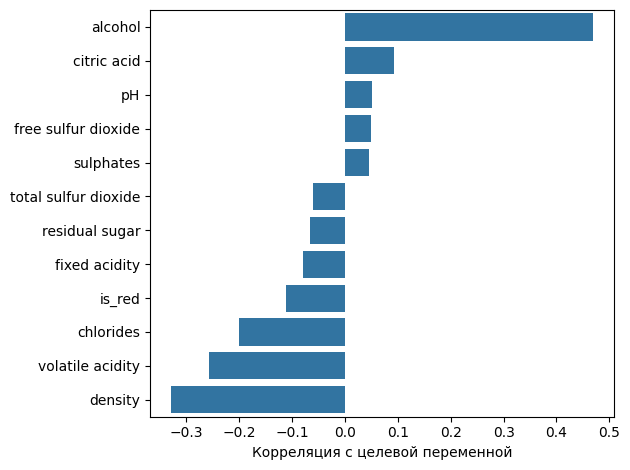

In [ ]:
correlations = X_train.corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations)

plot.set(xlabel="Корреляция с целевой переменной", ylabel="")

plt.tight_layout()
plt.show()

Наиболее сильная положительная корреляция наблюдается у `alcohol` (0.45) — более крепкие вина в среднем получают более высокие оценки дегустаторов, поэтому признак станет главным предиктором. Умеренная отрицательная корреляция у `density` (-0.31), `volatile acidity` (-0.26, избыток летучих кислот даёт резкий уксусный привкус и снижает оценку) и `chlorides` (-0.20, избыточная солёность).

<Axes: >

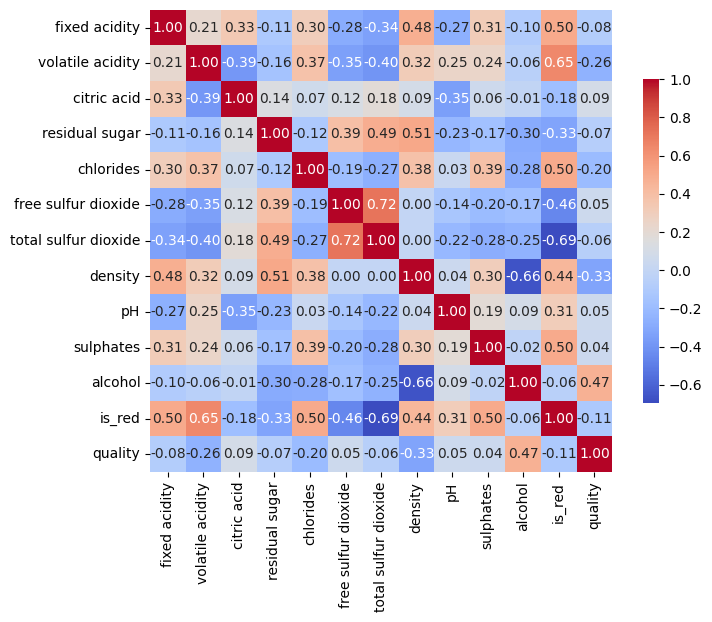

In [ ]:
corr_matrix = train.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar_kws={'shrink': 0.7})

Выявлена сильная взаимная корреляция между признаками: `free sulfur dioxide` и `total sulfur dioxide` (0.72), `density` и `alcohol` (-0.67, спирт менее плотный, чем вода), `density` и `residual sugar` (0.53), а также между `is_red` и `total sulfur dioxide` (-0.69). Это нужно учитывать при интерпретации весов линейной регрессии.

# **Подготовка выборок и обучение моделей**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

Признаки отмасштабированы через `StandardScaler` (обучен только на `X_train`). Для обычной линейной регрессии без регуляризации масштабирование не меняет качество прогноза, но необходимо для интерпретации коэффициентов: без него веса признаков в разных единицах измерения (`density` против `total sulfur dioxide`) нельзя сравнивать между собой

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

models = {
    'Baseline': DummyRegressor(strategy='mean'),
    'LinearRegression': LinearRegression(),
    'RandomForestRegressor': RandomForestRegressor(random_state=42),
    'GradientBoostingRegressor': GradientBoostingRegressor(random_state=42)
}

В качестве базового решения использован `DummyRegressor(strategy='mean')`, предсказывающий константу — среднее значение `quality` по обучающей выборке (5.80).

In [ ]:
rows = []
coefs = []

for name, model in models.items():
  model.fit(X_train_scaled, y_train)
  pred = model.predict(X_test_scaled)
  if hasattr(model, 'coef_'):
    coefs.append({'model': name, 'coef': model.coef_})
  elif hasattr(model, 'feature_importances_'):
    coefs.append({'model': name, 'coef': model.feature_importances_})
  rows.append({
      'model': name,
      'RMSE': root_mean_squared_error(y_test, pred),
      'MAE': mean_absolute_error(y_test, pred),
  })

`MAE` показывает среднюю абсолютную ошибку ($\frac{1}{n}\sum \vert{}y_i - \hat{y}_i\vert{}$) — на сколько баллов качества в среднем ошибается модель.

`RMSE` - это корень из среднеквадратичной ошибки ($\sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$) — среднеквадратичное отклонение предсказаний от истинных ответов в исходных единицах измерения

`RMSE` сильнее реагирует на большие ошибки из-за возведения ошибок в квадрат перед усреднением крупные промахи получают квадратично больший вес, тогда как в `MAE` все ошибки учитываются линейно

Чем больше дисперсия ошибок и чем чаще встречаются грубые выбросы на отдельных объектах (в нашей задаче — на редких классах 3, 4, 8, 9), тем сильнее `RMSE` превышает `MAE`

In [ ]:
results = pd.DataFrame(rows).sort_values("RMSE")
results

,model,RMSE,MAE
2,RandomForestRegressor,0.691117,0.533891
3,GradientBoostingRegressor,0.693991,0.538985
1,LinearRegression,0.729242,0.566001
0,Baseline,0.880102,0.694790


Все обученные модели превзошли `baseline`, но порог `RMSE` < 0.70 преодолели только `Random Forest` (0.6911) и `Gradient Boosting` (0.6940). Качество вина нелинейно зависит от сочетания физико-химических свойств (например, баланса кислоты, сахара и спирта), а в признаках присутствуют асимметрия и выбросы. Деревья решений эффективно улавливают нелинейные взаимодействия.

Линейная регрессия превзошла `baseline` (0.7292), но не прошла порог 0.70, так как способна восстанавливать только линейные зависимости и чувствительна к мультиколлинеарности и выбросам.

Случайный лес с параметрами по умолчанию показал немного лучший результат на тесте (0.6911) чем градиентный бустинг(0,694)

# **Feature importance**

In [ ]:
def show_weights(features, weights, title, ax=None):
    if ax is None:
      fig, ax = plt.subplots(figsize=(8, 6))

    sorted_weights = sorted(zip(weights, features), reverse=True)
    weights = [x[0] for x in sorted_weights]
    features = [x[1] for x in sorted_weights]

    sns.barplot(y=features, x=weights, ax=ax)
    ax.set_xlabel("Weight")


    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel("Вес признака", fontsize=11)
    ax.set_ylabel("")
    ax.axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
    ax.grid(axis='x', linestyle=':', alpha=0.6)
    sns.despine(ax=ax, left=False, bottom=False)

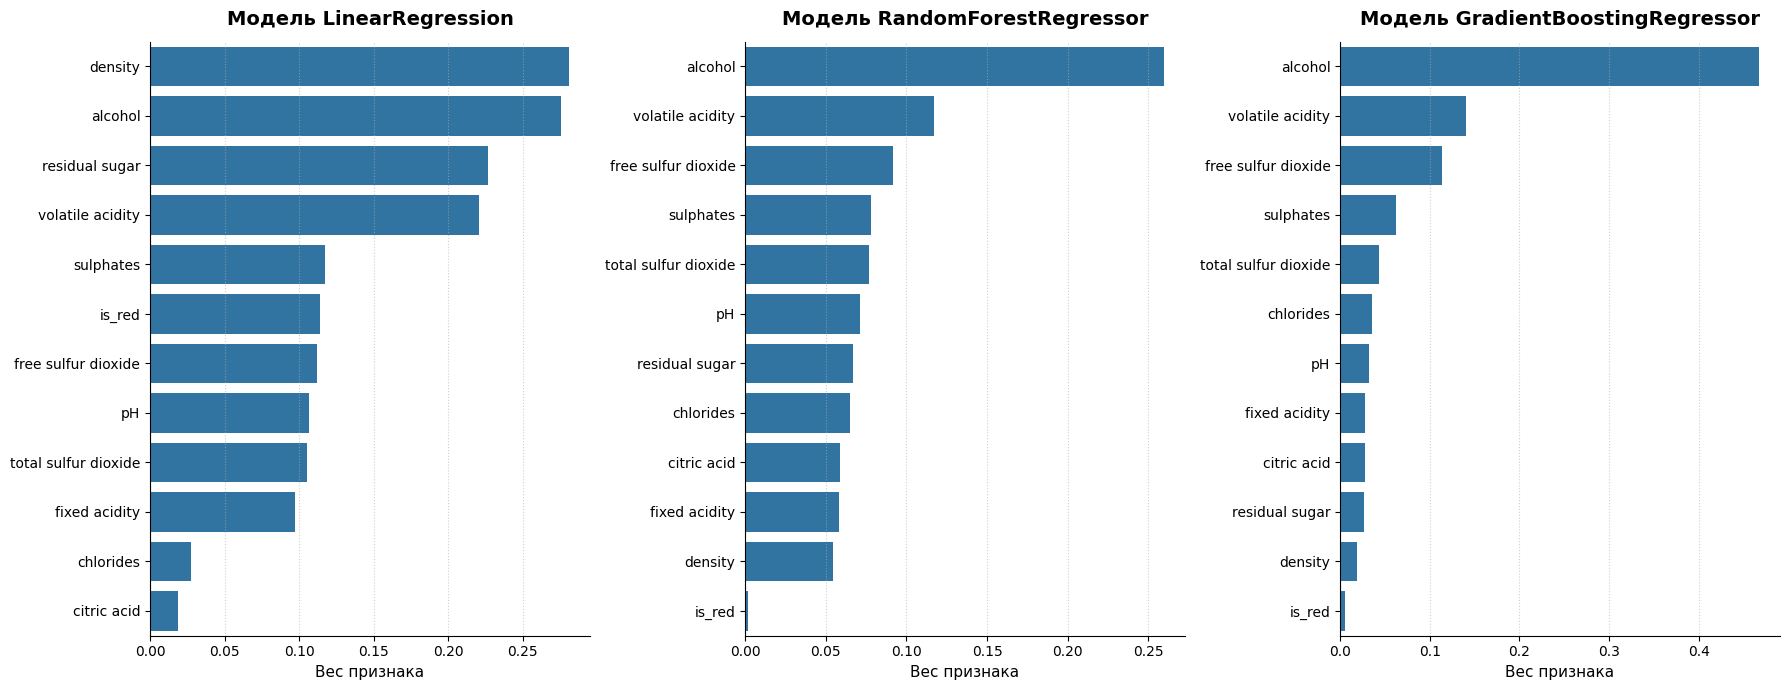

In [ ]:
n_models = len(coefs)
fig, axes = plt.subplots(ncols=n_models, figsize=(6 * n_models, 7))


for ax, model_info in zip(axes, coefs):
  name = model_info['model']
  coef = abs(model_info['coef'])
  show_weights(X.columns, coef, f'Модель {name}', ax=ax)

plt.tight_layout()
plt.show()




`Linear Regression`: Наибольшие по модулю стандартизованные коэффициенты получили `density`, `alcohol`, `residual sugar`, `volatile acidity` и `sulphates`. Выход `density` на 1-е место и высокий вес `residual sugar` (при его околонулевой корреляции с таргетом 0.04) вызваны сильной мультиколлинеарностью между плотностью, спиртом и сахаром — линейная модель искусственно завышает их веса с противоположными знаками для взаимной компенсации.   

`Random Forest` и `Gradient Boosting`: Оба алгоритма выделили практически одинаковый топ-5 признаков: `alcohol` (безусловный лидер), `volatile acidity`, `free sulfur dioxide`, `sulphates` и `total sulfur dioxide`. Это полностью согласуется с выводами EDA по главным факторам (`alcohol` и `volatile acidity`). При этом `density` у обеих моделей оказался на предпоследнем месте (деревьям он не нужен, так как информация уже учтена через спирт и сахар), а `free/total sulfur dioxide` вошли в топ за счёт нелинейного влияния на сохранность и вкус вина.

# **Анализ ошибок**

<Axes: ylabel='Count'>

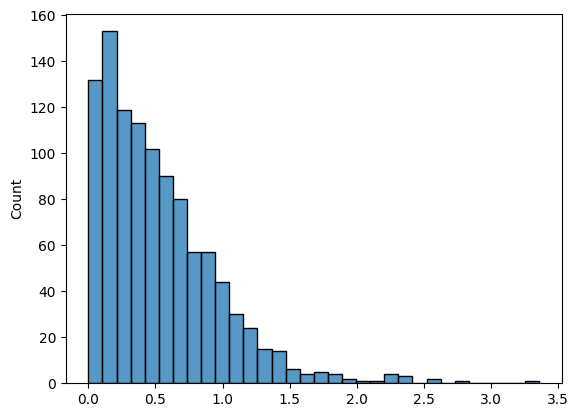

In [ ]:
model = RandomForestRegressor(random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = pd.Series(model.predict(X_test_scaled), index=y_test.index)
error = (y_test - y_pred).abs()
sns.histplot(error)


In [ ]:
df_results = pd.DataFrame({
    'y_true':y_test,
    'y_pred':y_pred.round(2),
    'error': error.round(2),
})

Распределение абсолютных ошибок лучшей модели (`RandomForestRegressor`) сконцентрировано вблизи нуля (большинство ошибок < 0.6), но имеет правый хвост до 3.36 балла

In [ ]:
df_results.groupby('y_true')['error'].agg(['count', 'mean', 'median'])

,count,mean,median
y_true,,,
3,6,2.288333,2.245
4,41,1.195854,1.140
5,350,0.434000,0.325
6,465,0.412151,0.360
7,171,0.660175,0.630
8,30,1.516667,1.450
9,1,3.360000,3.360


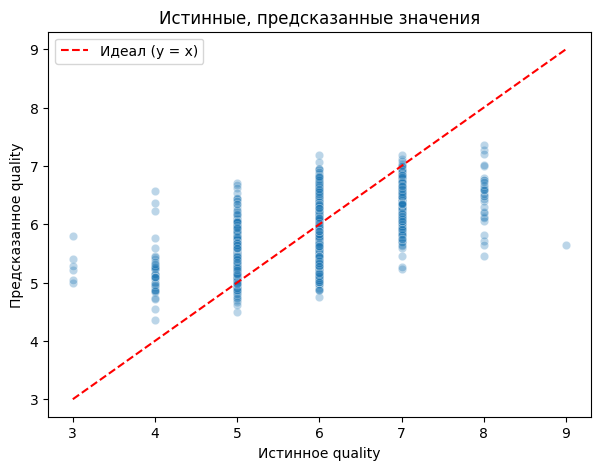

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Идеал (y = x)')
plt.xlabel('Истинное quality')
plt.ylabel('Предсказанное quality')
plt.title('Истинные, предсказанные значения')
plt.legend()
plt.show()

На массовых классах 5 и 6 средняя абсолютная ошибка минимальна (0.43 и 0.41), на классе 7 — умеренная (0.66). Модель работает неравномерно для разных оценок `quality`. На редких классах ошибка резко растёт: для 4 — в среднем 1.20, для 8 — 1.52, для 3 — 2.29, для 9 — 3.36

In [ ]:
df_max = df_results.nlargest(20, 'error').reset_index()
df_max

,index,y_true,y_pred,error
0,2012,9,5.64,3.36
1,1982,3,5.80,2.80
2,4984,4,6.57,2.57
3,2549,8,5.46,2.54
4,2783,3,5.41,2.41
5,4158,4,6.37,2.37
6,3881,8,5.65,2.35
7,3337,8,5.72,2.28
8,1571,3,5.28,2.28
9,3121,4,6.22,2.22


In [ ]:
max_idx = error.nlargest(n=5)
X_test.loc[max_idx.index]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red
2012,9.1,0.27,0.45,10.60,0.035,28.0,124.0,0.9970,3.20,0.46,10.4,0
1982,6.9,0.39,0.40,4.60,0.022,5.0,19.0,0.9915,3.31,0.37,12.6,0
4984,5.8,0.26,0.30,2.60,0.034,75.0,129.0,0.9902,3.20,0.38,11.5,0
2549,8.2,0.22,0.36,6.80,0.034,12.0,90.0,0.9944,3.01,0.38,10.5,0
2783,6.7,0.25,0.26,1.55,0.041,118.5,216.0,0.9949,3.55,0.63,9.4,0


Индекс 2012: белое вино со средним содержанием спирта (10.4%) и повышенным сахаром (10.6) — по признакам выглядит как рядовое вино класса 5–6, а примеров класса 9 в обучении было всего 4.

Индексы 1982 и 4984: имеют высокий градус алкоголя (12.6% и 11.5%) и умеренную летучую кислотность, что типично для хороших вин, поэтому модель дала завышенный прогноз. У образца 1982 при этом критически низкий уровень `free/total sulfur dioxide` (5.0 и 19.0), что для белого вина ведёт к окислению и потере вкуса. Кроме того, оценка дегустаторов субъективна и зависит от сложных дефектов, не описанных в 11 базовых признаках.

In [ ]:
df_min = df_results.nsmallest(20, 'error').reset_index()
df_min

,index,y_true,y_pred,error
0,2955,7,7.00,0.00
1,1956,5,5.00,0.00
2,1164,5,5.00,0.00
3,432,6,6.00,0.00
4,57,5,5.00,0.00
5,1380,6,6.01,0.01
6,4653,6,6.01,0.01
7,5303,6,5.99,0.01
8,997,6,5.99,0.01
9,4212,6,5.99,0.01


Модель хуже предсказывает редкие значения `quality`, потому что в обучающей выборке критически мало объектов с оценками 3 (24 шт.) и 9 (4 шт.), поэтому деревьям недостаточно данных для выделения этих областей признакового пространства. случайный лес усредняет ответы ста деревьев и оптимизирует среднеквадратичную ошибку, что математически стягивает предсказания к условному математическому ожиданию (к самым частым оценкам 5–6), сглаживая экстремальные прогнозы.